# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


### January 2024: Midtown-to-JFK raw-data check

Reproducible exploratory check using the January 2024 NYC yellow-taxi Parquet snapshot.
The file's SHA-256 is checked before analysis.


In [1]:
from pathlib import Path
import hashlib
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

path = data_dir / "yellow_tripdata_2024-01.parquet"
url = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/"
    "yellow_tripdata_2024-01.parquet"
)

if not path.exists():
    urllib.request.urlretrieve(url, path)

expected_hash = (
    "c4d59da7bbc8abaeeeb1727947ee93d9891"
    "a71acb42854bd80db1571b2030510"
)
actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()

assert actual_hash == expected_hash, "File differs from the documented snapshot."
print("January file downloaded and verified.")

January file downloaded and verified.


In [2]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
]

raw = pd.read_parquet(path, columns=columns)

trips = raw.loc[
    raw["PULocationID"].isin([161, 162, 163, 230])
    & raw["DOLocationID"].eq(132)
    & raw["tpep_pickup_datetime"].ge(pd.Timestamp("2024-01-01"))
    & raw["tpep_pickup_datetime"].lt(pd.Timestamp("2024-02-01"))
].copy()

trips["duration_minutes"] = (
    trips["tpep_dropoff_datetime"]
    - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# These are investigation flags—not automatic deletion rules.
trips["missing_duration"] = trips["duration_minutes"].isna()
trips["nonpositive_duration"] = trips["duration_minutes"].le(0)
trips["over_six_hours"] = trips["duration_minutes"].gt(360)
trips["duplicate_candidate"] = trips.duplicated(
    subset=columns, keep=False
)

display(trips[
    ["missing_duration", "nonpositive_duration",
     "over_six_hours", "duplicate_candidate"]
].sum().to_frame("Flagged rows"))

display(trips.loc[
    trips["over_six_hours"] | trips["duplicate_candidate"]
].head(20))

,Flagged rows
missing_duration,0
nonpositive_duration,0
over_six_hours,13
duplicate_candidate,110


,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,duration_minutes,missing_duration,nonpositive_duration,over_six_hours,duplicate_candidate
33839,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
33840,2024-01-01 12:23:34,2024-01-01 12:56:03,161,132,32.483333,False,False,False,True
49372,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
49373,2024-01-01 16:50:17,2024-01-01 17:27:11,161,132,36.900000,False,False,False,True
55489,2024-01-01 18:04:29,2024-01-02 17:35:05,230,132,1410.600000,False,False,True,False
91331,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
91332,2024-01-02 11:56:56,2024-01-02 12:50:45,230,132,53.816667,False,False,False,True
118292,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
118293,2024-01-02 17:35:05,2024-01-02 18:46:50,163,132,71.750000,False,False,False,True
122258,2024-01-02 17:08:45,2024-01-02 18:01:24,161,132,52.650000,False,False,False,True


,January trip duration (minutes)
count,6885.000000
mean,52.674561
std,50.805019
min,5.150000
50%,49.983333
90%,71.183333
95%,76.696667
99%,90.285333
max,1436.100000


Positive-duration trips: 6,885
Trips > 150 minutes (not displayed): 20 (0.29%)
Long trips remain in the dataset and duration summary statistics.


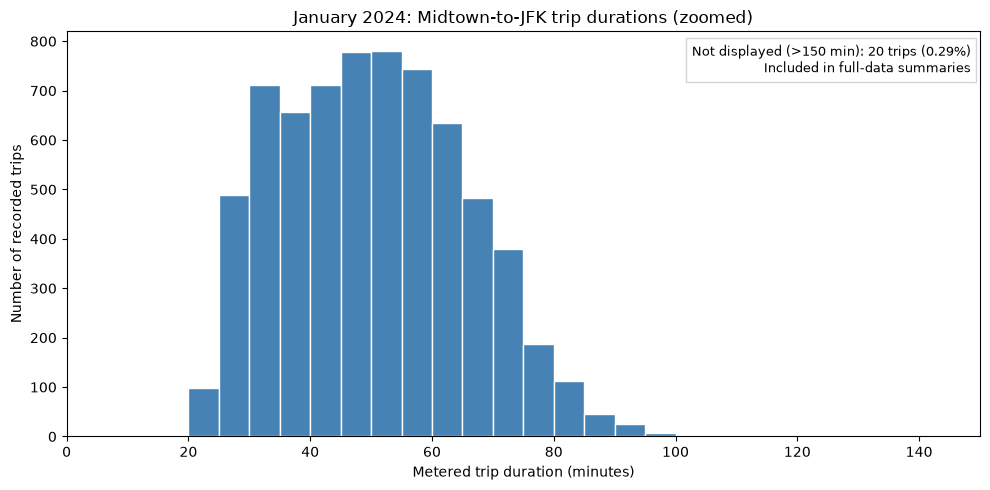

In [3]:
# Summarize positive trip durations without dropping unusually long trips.
positive = trips.loc[trips["duration_minutes"] > 0].copy()

display(
    positive["duration_minutes"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame("January trip duration (minutes)")
)

# The complete positive-duration dataset is retained for analysis and percentiles.
plot_max_minutes = 150
inside_plot = positive["duration_minutes"].le(plot_max_minutes)
outside_plot = positive["duration_minutes"].gt(plot_max_minutes)
outside_count = int(outside_plot.sum())
valid_count = len(positive)
outside_percent = 100 * outside_count / valid_count if valid_count else 0

print(f"Positive-duration trips: {valid_count:,}")
print(f"Trips > {plot_max_minutes} minutes (not displayed): "
      f"{outside_count:,} ({outside_percent:.2f}%)")
print("Long trips remain in the dataset and duration summary statistics.")

fig, ax = plt.subplots(figsize=(10, 5))
# The histogram shows only the visible range; this is a visualization choice,
# not a filtering rule for the underlying dataset.
visible_durations = positive.loc[inside_plot, "duration_minutes"]
ax.hist(visible_durations, bins=range(0, plot_max_minutes + 6, 5),
        color="steelblue", edgecolor="white")
ax.set_xlim(0, plot_max_minutes)
ax.set_title("January 2024: Midtown-to-JFK trip durations (zoomed)")
ax.set_xlabel("Metered trip duration (minutes)")
ax.set_ylabel("Number of recorded trips")
ax.text(0.99, 0.97,
        f"Not displayed (>150 min): {outside_count:,} trips "
        f"({outside_percent:.2f}%)\n"
        "Included in full-data summaries",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "lightgray", "alpha": 0.95})
fig.tight_layout()

# This saves the real plot when the cell is executed with the January parquet data.
Path("fig").mkdir(exist_ok=True)
fig.savefig("fig/january_duration_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


### January 2024 data check — preliminary findings

The January 2024 Midtown-to-JFK data check contains **6,885 positive-duration trips**,
with a median metered duration of **49.98 minutes** and an empirical 90th percentile
of **71.18 minutes**. These results were recomputed by running the notebook and
independently reproduced by a teammate. This is an initial fixed-allowance benchmark
before February calibration, not a tested recommendation.

The data-quality checks flagged **0 missing durations**, **0 nonpositive durations**,
**13 trips over six hours**, and **110 rows belonging to potential duplicate groups**
based on timestamps and zones. Flagged records remain in the data pending
investigation rather than being automatically deleted.

### January 2024 duration histogram — visualization note

The histogram displays **0–150 minutes** to reveal the distribution of typical
Midtown-to-JFK trip durations. **20 trips (0.29%)** exceed 150 minutes and are
outside the displayed range, but remain in the complete dataset and duration
summaries, including the reported percentiles. The plot is saved as
`fig/january_duration_histogram.png`.

Metered trip duration excludes additional airport procedures and time spent
before entering the taxi, so these results describe the road portion of the journey.


### Days the allowance does not cover (issue #3)

The allowance is meant for ordinary days. A day is flagged if, by 6 pm the day before, it met one of three rules:
(R1) a US federal holiday; (R2) a publicly announced event with street closures inside pickup zones 161, 162, 163
or 230, or on FDR Drive; (R3) an NWS Winter Storm, Blizzard, Ice Storm, Flood or Flash Flood Warning for Manhattan
or Queens. `events.py` lists every candidate day that was checked, flagged or not, with its source. The same rules
and sources apply to January, February and March. Unannounced disruptions, such as the 8 January protest, stay ordinary.


In [4]:
import events

events.candidates()


,date,rule,flagged,what,source
0,2024-01-01,R1,True,New Year's Day,federal holiday (OPM)
1,2024-01-08,R2,False,"Bridge and tunnel protest, 9:40-11:15 am","not announced in advance (NBC New York, ABC7)"
2,2024-01-09,R3,False,"Rain and wind: Flood Watch, High Wind Warning,...",watch only; high wind is not an R3 type; flood...
3,2024-01-10,R3,False,Flood Warning overnight from 9 Jan; Coastal Fl...,"flood warning issued 9:34 pm on 9 Jan, after t..."
4,2024-01-13,R3,False,Coastal Flood Warning,coastal flood is not an R3 type (Iowa Environm...
5,2024-01-15,R1,True,Martin Luther King Jr. Day,federal holiday (OPM)
6,2024-01-16,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...
7,2024-01-19,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...
8,2024-02-13,R3,True,Nor'easter,"Winter Storm Warning issued 4:00 pm on 12 Feb,..."
9,2024-02-17,R3,False,Snow,Winter Weather Advisory only (Iowa Environment...


In [5]:
# January and February only: March is not looked at before it is scored.
feb_path = data_dir / "yellow_tripdata_2024-02.parquet"
if not feb_path.exists():
    urllib.request.urlretrieve(url.replace("2024-01", "2024-02"), feb_path)
assert hashlib.sha256(feb_path.read_bytes()).hexdigest() == (
    "c76c43c18c6c6664080dd920baab4928988d5786a6b65980792ca7cd796f9f20"
), "File differs from the documented snapshot."

feb_raw = pd.read_parquet(feb_path, columns=columns)
feb = feb_raw.loc[
    feb_raw["PULocationID"].isin([161, 162, 163, 230])
    & feb_raw["DOLocationID"].eq(132)
    & feb_raw["tpep_pickup_datetime"].ge(pd.Timestamp("2024-02-01"))
    & feb_raw["tpep_pickup_datetime"].lt(pd.Timestamp("2024-03-01"))
].copy()
feb["duration_minutes"] = (
    feb["tpep_dropoff_datetime"] - feb["tpep_pickup_datetime"]
).dt.total_seconds() / 60

jan_feb = events.flag_days(pd.concat([
    positive[columns + ["duration_minutes"]],
    feb.loc[feb["duration_minutes"] > 0, columns + ["duration_minutes"]],
]))
jan_feb["month"] = jan_feb["tpep_pickup_datetime"].dt.strftime("%Y-%m")
jan_feb["date"] = jan_feb["tpep_pickup_datetime"].dt.date

display(jan_feb.groupby("month").agg(
    trips=("flagged_day", "size"), trips_on_flagged_days=("flagged_day", "sum")
))

daily = (
    jan_feb.groupby(["date", "flagged_day", "flag_rule"])["duration_minutes"]
    .agg(trips="size", median="median", p90=lambda s: s.quantile(0.9))
    .reset_index()
)
ordinary = daily.loc[~daily["flagged_day"]]
display(daily.loc[daily["flagged_day"]].round(1))
print(f"Ordinary days: {len(ordinary)}; median daily median {ordinary['median'].median():.1f} min; "
      f"daily 90th percentile from {ordinary['p90'].quantile(0.1):.1f} to {ordinary['p90'].quantile(0.9):.1f} min "
      f"(10th to 90th percentile of days); median {ordinary['trips'].median():.0f} trips a day.")


,trips,trips_on_flagged_days
month,,
2024-01,6885,629
2024-02,6505,428


,date,flagged_day,flag_rule,trips,median,p90
0,2024-01-01,True,R1,373,43.3,69.7
14,2024-01-15,True,R1,256,42.3,58.7
43,2024-02-13,True,R3,148,34.0,44.6
49,2024-02-19,True,R1,280,41.4,54.4


Ordinary days: 56; median daily median 54.0 min; daily 90th percentile from 49.8 to 81.6 min (10th to 90th percentile of days); median 214 trips a day.


**Flagged days in January and February.** The rules flag four days: 1 and 15 January, 13 and 19 February. They hold
629 of January's 6,885 trips and 428 of February's 6,505 (counted before cleaning; after cleaning, 623 and 423, see the Split section). The flagged days stand out on the fast side: their daily
median runs from 34 to 43 minutes, against 54 minutes on a typical ordinary day, and the snow day (13 February,
schools remote) was the fastest, with a 90th percentile of 44.6 minutes. Holidays and the storm emptied the roads
rather than jamming them. Leaving these days in the January fit and the February offset would pull the allowance
down for ordinary days, so they are removed from both, for the model and the fixed allowance alike.


### Cleaning the records

`taxi.py` loads the three months with the hash check and flags three kinds of record (2026-11-08 entry):
reversal copies (a voided payment: same times, zones and distance as a real trip, with a negative fare),
non-positive durations, and meters left running over six hours. Reversal copies and non-positive durations
are dropped; trips over six hours are left out of the fit and the main score and come back in a sensitivity.
March is used only for these prespecified record-quality checks: its durations are computed to flag
non-positive and over-six-hour records, and only the counts are shown. March is not used for fitting,
calibration, choosing features, or comparing the methods until it is scored once.


In [1]:
import taxi

records = taxi.records()
records["month"] = records["tpep_pickup_datetime"].dt.strftime("%Y-%m")
display(records.groupby("month").agg(
    records=("flag_reversal", "size"),
    reversal_copies=("flag_reversal", "sum"),
    non_positive=("flag_nonpositive", "sum"),
    over_six_hours=("flag_over_6h", "sum"),
))


,records,reversal_copies,non_positive,over_six_hours
month,,,,
2024-01,6885,55,0,13
2024-02,6505,87,0,9
2024-03,8336,124,1,15


## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [3]:
import pandas as pd

trips = taxi.trips(records)

display(pd.DataFrame(taxi.SPLIT, index=["from", "to (exclusive)"]).T)
display(trips.groupby("split", sort=False).agg(
    trips=("flagged_day", "size"),
    ordinary_day_trips=("flagged_day", lambda s: int((~s).sum())),
))


,from,to (exclusive)
fit,2024-01-01,2024-02-01
calibrate,2024-02-01,2024-03-01
test,2024-03-01,2024-04-01


,trips,ordinary_day_trips
split,,
fit,6817,6194
calibrate,6409,5986
test,8196,7635


**Split.** Fit on January, calibrate the additive offset on February, score March once (2026-11-08 entry).
Fit and calibration use ordinary days only (2026-11-07 entry). March is scored on ordinary days and on all days.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [4]:
# Fixed baseline: fit January, calibrate February; do not read March outcomes here.
from baseline import january_p90, calibrate_fixed_p90
import scoring

jan_ordinary = trips.loc[
    (trips["split"] == "fit") & (~trips["flagged_day"]), "duration_minutes"
].to_numpy()
feb_ordinary = trips.loc[
    (trips["split"] == "calibrate") & (~trips["flagged_day"]), "duration_minutes"
].to_numpy()

jan_allowance = january_p90(jan_ordinary)
feb_offset, fixed_allowance = calibrate_fixed_p90(jan_allowance, feb_ordinary)

print(f"January ordinary-day sample: {len(jan_ordinary):,} trips")
print(f"February ordinary-day sample: {len(feb_ordinary):,} trips")
print(f"January fixed P90: {jan_allowance:.2f} minutes")
print(f"February additive offset: {feb_offset:+.2f} minutes")
print(f"Frozen fixed baseline: {fixed_allowance:.2f} minutes")
print(f"February calibrated coverage (diagnostic): {scoring.coverage(feb_ordinary, fixed_allowance):.1%}")


January ordinary-day sample: 6,194 trips
February ordinary-day sample: 5,986 trips
January fixed P90: 71.28 minutes
February additive offset: +4.72 minutes
Frozen fixed baseline: 76.00 minutes
February calibrated coverage (diagnostic): 90.0%


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
